# Chapitre 5 - Exercices 5.7 à 5.12

Ce notebook traite six exercices sur les bonnes pratiques (cours 3) et l'ingénierie défensive
(cours 4) :

- **5.7** : sortie JSON fiable : probabilité de succès avec relances, coût espéré (calcul + mini-lab) ;
- **5.8** : chaîne de pensée : coût par bonne réponse et auto-cohérence par vote majoritaire ;
- **5.9** : deux versions de prompt sont-elles vraiment différentes ? test de McNemar et taille d'échantillon ;
- **5.10** : détecteur d'injection : courbe ROC, seuil, contournement, détecteur sémantique ;
- **5.11** : défense en profondeur : combiner des couches, hypothèse d'indépendance vs mesure ;
- **5.12** : injection indirecte dans un mini-RAG et défenses côté recherche, prompt et sortie.

In [1]:
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score

from aie import llm
from aie import ch05_prompts as P
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)
tok = P._tokenizer(llm.SMALL)
pool, test = P.split_intents(4, seed=0)
y_true = [y for _, y in test]

## Exercice 5.7 : Sortie JSON fiable avec relances

**Énoncé.** Une application a besoin d'un JSON `{"categorie", "urgence"}` valide. Chaque appel
réussit (JSON valide avec les bonnes clés) avec une probabilité $p$, indépendamment des autres
appels si l'on échantillonne avec une température non nulle. On autorise jusqu'à $r$ tentatives.

1. Exprimer la probabilité de succès final $S(r)$ et le nombre **espéré** d'appels $E(r)$.
2. Estimer $p$ sur Qwen (température 0,7, 20 messages) pour le prompt explicite du cours 3,
   puis vérifier empiriquement $S(r)$ pour $r = 1, 2, 3$.
3. Combien de tentatives faut-il pour atteindre 99 % de succès ?

**Rappels.** Spécifier le format de sortie (cours 3, section 3) ; le livre cite les outils de
sorties structurées (Outlines, Instructor, Guidance) et rappelle que chaque validation ou
relance est un appel d'API de plus (section *Evaluate Prompt Engineering Tools*).

**Solution (1).** Les échecs sont indépendants, donc la probabilité d'échouer $r$ fois est
$(1-p)^r$ et $S(r) = 1 - (1-p)^r$. Le $i$-ème appel a lieu si les $i-1$ précédents ont échoué :
$$E(r) = \sum_{i=1}^{r} (1-p)^{i-1} = \frac{1 - (1-p)^r}{p} = \frac{S(r)}{p}.$$
Pour atteindre une cible $S^\star$ : $r \geq \frac{\ln(1 - S^\star)}{\ln(1-p)}$.

In [2]:
CONSIGNE = ('Analyse ce message de client. Réponds UNIQUEMENT par un objet JSON avec exactement deux clés : '
            '"categorie" (livraison, remboursement, technique ou compte) et "urgence" (basse, moyenne ou haute). '
            "Aucun texte avant ou après.")

def valide(out):
    obj, statut = P.parse_json_output(out)
    return statut == "ok" and isinstance(obj, dict) and set(obj) == {"categorie", "urgence"}

R = 3
essais = []
for i, (x, _) in enumerate(test[:20]):
    for t in range(R):
        out = llm.chat(f"{CONSIGNE}\n\nMessage : {x}", temperature=0.7, seed=100 * i + t, max_new_tokens=50)
        essais.append(dict(message=i, tentative=t, ok=valide(out)))
essais = pd.DataFrame(essais)
p_hat = essais.ok.mean()
print(f"p estimé (strict : JSON pur, bonnes clés) = {p_hat:.2f} sur {len(essais)} appels")

emp = []
for r in range(1, R + 1):
    succes = essais[essais.tentative < r].groupby("message").ok.any().mean()
    appels = essais.groupby("message").apply(lambda g: min(r, (g.ok.values.argmax() + 1) if g.ok.any() else r),
                                             include_groups=False).mean()
    emp.append(dict(r=r, S_theorique=1 - (1 - p_hat) ** r, S_mesure=succes,
                    E_theorique=(1 - (1 - p_hat) ** r) / p_hat if p_hat > 0 else np.nan, E_mesure=appels))
emp = pd.DataFrame(emp)
emp.round(3)

p estimé (strict : JSON pur, bonnes clés) = 0.50 sur 60 appels


,r,S_theorique,S_mesure,E_theorique,E_mesure
0,1,0.500,0.65,1.00,1.00
1,2,0.750,0.80,1.50,1.35
2,3,0.875,0.90,1.75,1.55


**Vérification** graphique et réponse à la question 3.

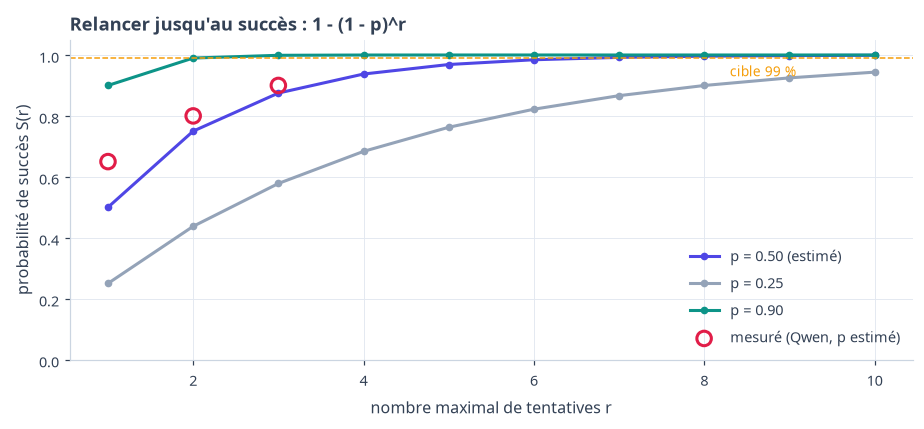

tentatives nécessaires pour 99 % avec p = 0.50 : r >= 6.6


In [3]:
rr = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(8.5, 4))
for p, c in [(p_hat, INDIGO), (0.25, GRAY), (0.9, TEAL)]:
    ax.plot(rr, 1 - (1 - p) ** rr, "o-", color=c, ms=4, label=f"p = {p:.2f}" + (" (estimé)" if c == INDIGO else ""))
ax.scatter(emp.r, emp.S_mesure, s=90, facecolor="none", edgecolor=ROSE, lw=2, zorder=4, label="mesuré (Qwen, p estimé)")
ax.axhline(0.99, color=AMBER, ls="--", lw=1)
ax.text(8.3, 0.93, "cible 99 %", color=AMBER, fontsize=9)
ax.set_xlabel("nombre maximal de tentatives r")
ax.set_ylabel("probabilité de succès S(r)")
ax.set_ylim(0, 1.05)
ax.set_title("Relancer jusqu'au succès : 1 - (1 - p)^r")
ax.legend(loc="lower right")
finish(fig)
plt.show()
if 0 < p_hat < 1:
    print(f"tentatives nécessaires pour 99 % avec p = {p_hat:.2f} : r >= {np.log(0.01) / np.log(1 - p_hat):.1f}")

**Lecture.** Si $p$ est élevé, une ou deux relances suffisent et le surcoût moyen $E(r) - 1$
reste faible : les relances sont un filet de sécurité bon marché. Si $p$ est faible, les
relances deviennent coûteuses et lentes : mieux vaut améliorer le prompt, analyser de façon
tolérante (`parse_json_output` récupère les JSON entourés de texte) ou contraindre le décodage.
Attention à l'hypothèse d'indépendance : à température 0, toutes les tentatives sont
identiques et la relance est inutile ; et certains messages sont « difficiles » pour toutes les
tentatives. Plus généralement, $p$ varie d'un message à l'autre (et ici d'une tentative à
l'autre) : $S(r)$ mesuré s'écarte alors de la courbe théorique, et avec des messages
« impossibles » il plafonne sous 1 alors que la formule promet 1.

> **À retenir.** Avec des tentatives indépendantes, $S(r) = 1 - (1-p)^r$ et
> $E(r) = S(r)/p$ : les relances sont efficaces quand $p$ est déjà bon, et n'ont de sens qu'avec
> un échantillonnage non déterministe.

## Exercice 5.8 : Chaîne de pensée, coût par bonne réponse et auto-cohérence

**Énoncé.** Sur 10 problèmes d'arithmétique, comparer : (a) réponse directe ; (b) chaîne de
pensée gloutonne ; (c) **auto-cohérence** (*self-consistency*, Wang et al. 2022) : 5 chaînes de
pensée échantillonnées (température 0,7) et vote majoritaire sur la réponse finale. Calculer
pour chaque méthode la précision, le nombre de tokens générés et le **coût par bonne réponse**
(tokens générés / nombre de bonnes réponses).

**Rappels.** Chaîne de pensée et coût en latence (cours 3, section 6, section du livre *Give the
Model Time to Think*). L'auto-cohérence suppose que les chaînes de raisonnement correctes
convergent vers la même réponse alors que les erreurs se dispersent.

**Solution.** Pour (c), on génère les 5 chaînes **en un seul lot** (`num_return_sequences=5`),
ce qui amortit le préremplissage du prompt.

In [4]:
COT = "Réfléchis étape par étape en montrant les calculs, puis termine par une ligne « Réponse : <nombre> »."
DIRECT = "Réponds uniquement par le nombre final, sans explication."
tk, model = llm.load(llm.SMALL)

def echantillons_cot(question, n=5, temperature=0.7, max_new_tokens=280, seed=0):
    msgs = [{"role": "user", "content": f"{question}\n{COT}"}]
    ids = tk.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(model.device)
    llm.seed_everything(seed)
    with torch.no_grad():
        out = model.generate(**ids, do_sample=True, temperature=temperature, top_p=1.0, num_return_sequences=n,
                             max_new_tokens=max_new_tokens, pad_token_id=tk.pad_token_id)
    gens = out[:, ids["input_ids"].shape[1]:]
    textes = tk.batch_decode(gens, skip_special_tokens=True)
    n_tok = [int((g != tk.pad_token_id).sum()) for g in gens]
    return textes, n_tok

PB = P.MATH_PROBLEMS[:10]
rows = []
for i, (q, a) in enumerate(PB):
    d = llm.chat(f"{q}\n{DIRECT}", max_new_tokens=12)
    c = llm.chat(f"{q}\n{COT}", max_new_tokens=280)
    textes, n_tok = echantillons_cot(q, seed=i)
    votes = [P.extract_number(t) for t in textes]
    votes_valides = [v for v in votes if v is not None]
    maj = Counter(votes_valides).most_common(1)[0][0] if votes_valides else None
    rows.append(dict(attendu=a, direct=P.extract_number(d), cot=P.extract_number(c), vote=maj, votes=votes,
                     tok_direct=len(tk(d)["input_ids"]), tok_cot=len(tk(c)["input_ids"]), tok_vote=sum(n_tok)))
sc = pd.DataFrame(rows)
bilan = pd.DataFrame({m: {"bonnes réponses (/10)": int((sc[m] == sc.attendu).sum()),
                          "tokens générés (total)": int(sc[f"tok_{m}"].sum())} for m in ["direct", "cot", "vote"]}).T
bilan["tokens par bonne réponse"] = (bilan["tokens générés (total)"] / bilan["bonnes réponses (/10)"].replace(0, np.nan)).round(0)
bilan.index = ["réponse directe", "CoT gloutonne", "auto-cohérence (5 votes)"]
bilan

,bonnes réponses (/10),tokens générés (total),tokens par bonne réponse
réponse directe,3,23,8.0
CoT gloutonne,6,1644,274.0
auto-cohérence (5 votes),6,9298,1550.0


**Vérification** graphique : précision en fonction du coût.

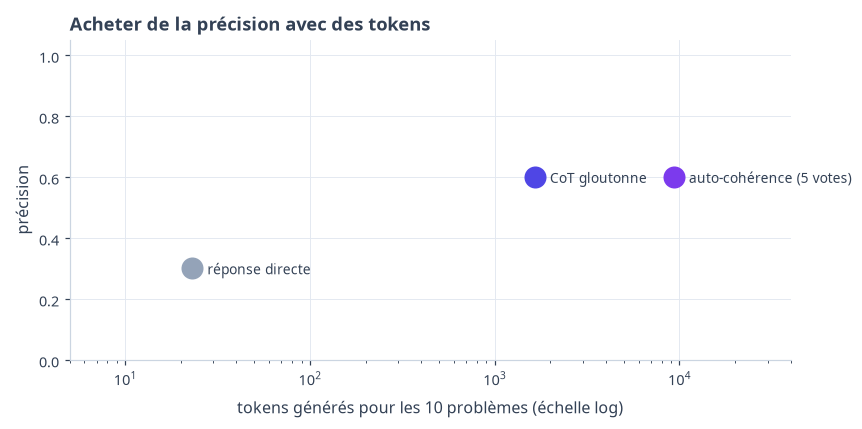

,attendu,cot,vote,votes
0,15,15,25,"[25, 15, 13, 25, 20]"
1,21,21,21,"[21, 24, 7, 21, 21]"
2,103,173,15,"[15, 103, 4, 37, 137]"
3,90,6,90,"[90, 60, None, 90, 90]"
4,29,29,29,"[29, None, 29, 29, 5]"


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for (nom, r), c in zip(bilan.iterrows(), [GRAY, INDIGO, VIOLET]):
    ax.scatter(r["tokens générés (total)"], r["bonnes réponses (/10)"] / 10, s=180, color=c, zorder=3)
    ax.annotate(nom, (r["tokens générés (total)"], r["bonnes réponses (/10)"] / 10), textcoords="offset points",
                xytext=(10, -4), fontsize=9)
ax.set_xscale("log")
ax.set_xlim(5, 4e4)
ax.set_ylim(0, 1.05)
ax.set_xlabel("tokens générés pour les 10 problèmes (échelle log)")
ax.set_ylabel("précision")
ax.set_title("Acheter de la précision avec des tokens")
finish(fig)
plt.show()
sc[["attendu", "cot", "vote", "votes"]].head(5)

**Lecture.** La chaîne de pensée multiplie les tokens générés par un facteur de l'ordre de 50 à
100 par rapport à la réponse directe, pour une précision environ doublée : le coût **par bonne
réponse** augmente donc nettement. L'investissement se justifie quand une erreur coûte plus cher
que les tokens (un calcul de facture, un dosage). L'auto-cohérence coûte environ 5 fois plus que
la CoT gloutonne ; son gain dépend de la dispersion des erreurs (colonne `votes`) : sur un modèle
de 0,5 B, les chaînes échantillonnées sont souvent fausses de façons différentes, et le vote
majoritaire peut n'apporter aucune bonne réponse de plus. Pour une application
interactive, ces tokens se paient aussi en **latence** (le livre insiste sur la latence perçue).

> **À retenir.** On compare les méthodes de raisonnement par leur précision **et** leur coût par
> bonne réponse. La chaîne de pensée achète de la précision avec beaucoup de tokens ;
> l'auto-cohérence multiplie encore ce coût par 5, pour un gain qui dépend du modèle.

## Exercice 5.9 : Deux versions de prompt sont-elles vraiment différentes ?

**Énoncé.** Le registre du cours 3 contient deux descriptions de la tâche d'intentions : la v1
(originale) et la v2 (frontières précisées). (1) Évaluer les deux en zéro-shot sur les 40
messages de test et construire le tableau des désaccords. (2) Appliquer le **test de McNemar**
exact. (3) Combien de messages de test faudrait-il pour détecter de façon fiable un écart de 5
points de précision ?

**Rappels.** Le livre demande de versionner les prompts et de standardiser métriques et données
d'évaluation pour les comparer (section *Iterate on Your Prompts*). Les deux versions sont
évaluées sur les **mêmes** messages : les mesures sont **appariées**. Le test de McNemar n'utilise
que les désaccords : $b$ = messages justes avec v1 seulement, $c$ = justes avec v2 seulement.
Sous l'hypothèse nulle (pas de différence), $b \sim \mathcal B(b + c, 1/2)$.

**Solution (1) et (2).**

In [6]:
DESC_V2 = (P.INTENT_DESCRIPTION + " Un problème de colis (retard, colis abîmé, article manquant, frais de port) "
           "relève de livraison, même si le client parle d'argent. Un problème de connexion ou d'identifiant relève de compte.")
reg = P.PromptRegistry()
reg.register("intention_client", P.INTENT_DESCRIPTION, note="v1")
reg.register("intention_client", DESC_V2, note="v2 frontières")
juste = {}
for v in [1, 2]:
    labs, _ = P.predictions(test, [], description=reg.get("intention_client", v).text)
    juste[v] = np.array([a == b for a, b in zip(labs, y_true)])
    reg.log_metric("intention_client", v, "precision", juste[v].mean())
b = int((juste[1] & ~juste[2]).sum())
c = int((~juste[1] & juste[2]).sum())
p_mcnemar = stats.binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
print(f"précision v1 = {juste[1].mean():.3f}, v2 = {juste[2].mean():.3f}")
print(f"désaccords : b (v1 seule juste) = {b}, c (v2 seule juste) = {c} ; p-valeur McNemar exacte = {p_mcnemar:.4f}")
pd.crosstab(pd.Series(juste[1], name="v1 juste"), pd.Series(juste[2], name="v2 juste"))

précision v1 = 0.475, v2 = 0.400
désaccords : b (v1 seule juste) = 6, c (v2 seule juste) = 3 ; p-valeur McNemar exacte = 0.5078


v2 juste,False,True
v1 juste,,
False,18,3
True,6,13


**Solution (3).** Pour un test apparié, la puissance dépend du taux de désaccord $\pi_d$ et de
l'écart $\Delta$. Approximation classique (Connor, 1987) pour un test bilatéral à 5 % avec 80 %
de puissance :
$$n \approx \frac{\left(z_{0{,}975}\sqrt{\pi_d} + z_{0{,}8}\sqrt{\pi_d - \Delta^2}\right)^2}{\Delta^2}.$$
On vérifie aussi par simulation.

In [7]:
def n_mcnemar(delta, pi_d, alpha=0.05, puissance=0.8):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(puissance)
    return (za * np.sqrt(pi_d) + zb * np.sqrt(pi_d - delta ** 2)) ** 2 / delta ** 2

def puissance_simulee(n, delta, pi_d, n_sim=2000, rng=np.random.default_rng(0)):
    pb, pc = (pi_d - delta) / 2, (pi_d + delta) / 2
    ok = 0
    for _ in range(n_sim):
        bb, cc, _ = rng.multinomial(n, [pb, pc, 1 - pb - pc])
        if bb + cc and stats.binomtest(int(bb), int(bb + cc), 0.5).pvalue < 0.05:
            ok += 1
    return ok / n_sim

pi_obs = (b + c) / len(test)
print(f"taux de désaccord observé : {pi_obs:.2f}")
rows = []
for pi_d in [0.1, 0.2, 0.3]:
    n = n_mcnemar(0.05, pi_d)
    rows.append(dict(taux_de_desaccord=pi_d, n_formule=int(np.ceil(n)), puissance_simulee_a_n=puissance_simulee(int(np.ceil(n)), 0.05, pi_d, 600)))
pd.DataFrame(rows)

taux de désaccord observé : 0.23


,taux_de_desaccord,n_formule,puissance_simulee_a_n
0,0.1,312,0.721667
1,0.2,626,0.778333
2,0.3,940,0.798333


**Vérification** graphique : puissance en fonction de la taille du jeu de test.

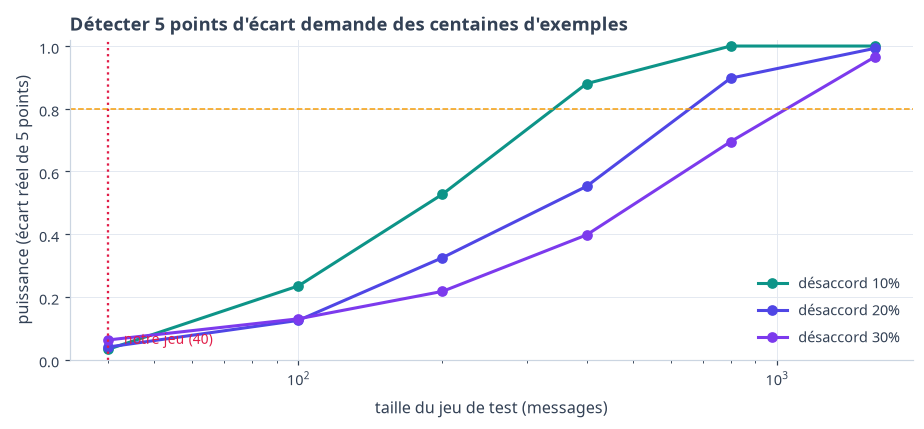

,nom,version,empreinte,modele,auteur,note,precision
0,intention_client,1,98121e7a53,Qwen2.5-0.5B-Instruct,,v1,0.475
1,intention_client,2,d4c7e5c18c,Qwen2.5-0.5B-Instruct,,v2 frontières,0.400


In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ns = [40, 100, 200, 400, 800, 1600]
for pi_d, col in [(0.1, TEAL), (0.2, INDIGO), (0.3, VIOLET)]:
    ax.plot(ns, [puissance_simulee(n, 0.05, pi_d, 400) for n in ns], "o-", color=col, label=f"désaccord {pi_d:.0%}")
ax.axhline(0.8, color=AMBER, ls="--", lw=1)
ax.axvline(len(test), color=ROSE, ls=":", lw=1.5)
ax.text(len(test) * 1.08, 0.05, "notre jeu (40)", color=ROSE, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("taille du jeu de test (messages)")
ax.set_ylabel("puissance (écart réel de 5 points)")
ax.set_ylim(0, 1.02)
ax.set_title("Détecter 5 points d'écart demande des centaines d'exemples")
ax.legend()
finish(fig)
plt.show()
reg.table()

**Lecture.** Avec 40 messages, seule une différence importante peut être déclarée
significative ; un écart de quelques points entre deux versions de prompt est le plus souvent
du bruit. Pour détecter 5 points d'écart, il faut plusieurs centaines d'exemples, d'autant plus
que les deux versions sont souvent en désaccord. Le registre garde la trace des deux versions et
de leurs métriques : on y ajoutera l'intervalle de confiance plutôt qu'un chiffre nu.

> **À retenir.** Comparer deux prompts sur le même jeu = test apparié (McNemar). La taille du jeu
> d'évaluation détermine les écarts détectables : 40 exemples ne départagent que des différences
> grossières.